# THỰC HÀNH 2.1: GIẢI THUẬT CÂY QUYẾT ĐỊNH VÀ RỪNG CÂY
**Decision Tree & Random Forest**

Notebook gồm hai bài thực hành:

| Bài | Bộ dữ liệu | Mục tiêu dự đoán |
|---|---|---|
| **Bài 1** | Titanic (`train.csv`, `test.csv`) | Hành khách có sống sót hay không (`Survived`) |
| **Bài 2** | Diabetes Prediction (`diabetes_prediction_dataset.csv`) | Bệnh nhân có mắc tiểu đường hay không (`diabetes`) |

Quy trình thực hiện cho mỗi bài: **đọc dữ liệu → kiểm tra chất lượng → khám phá (EDA) → tiền xử lý → cây quyết định → tìm tham số tối ưu bằng GridSearchCV → rừng cây → đánh giá và nhận xét**.

> Cách chạy trên Google Colab: tải 3 tệp `train.csv`, `test.csv`, `diabetes_prediction_dataset.csv` lên thư mục `/content`, sau đó chạy lần lượt các ô từ trên xuống.

## 0. Chuẩn bị chung

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import graphviz                      # vẽ cây quyết định
from sklearn import tree
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings('ignore')
%matplotlib inline
mpl.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')

# Thư mục chứa dữ liệu: /content nếu chạy trên Google Colab, ngược lại là thư mục hiện tại
DATA_DIR = '/content' if os.path.exists('/content') else '.'
RANDOM_STATE = 24     # cùng random seed với bài mẫu
N_FOLDS = 4           # số fold của cross-validation

Các hàm dùng chung cho cả hai bài: đánh giá mô hình, vẽ cây, vẽ biểu đồ kết quả GridSearchCV, vẽ độ quan trọng của đặc trưng, vẽ ma trận nhầm lẫn và đường ROC.

In [2]:
def evaluate(model, X_tr, y_tr, X_va, y_va, name):
    """Trả về bảng chỉ số trên tập huấn luyện và tập kiểm tra (để phát hiện overfitting)."""
    rows = []
    for split, X_, y_ in (('train', X_tr, y_tr), ('valid', X_va, y_va)):
        pred = model.predict(X_)
        proba = model.predict_proba(X_)[:, 1]
        rows.append({'model': name, 'tập': split,
                     'accuracy': accuracy_score(y_, pred),
                     'precision': precision_score(y_, pred, zero_division=0),
                     'recall': recall_score(y_, pred),
                     'f1': f1_score(y_, pred),
                     'roc_auc': roc_auc_score(y_, proba)})
    return pd.DataFrame(rows)


def show_tree(model, feature_names, class_names):
    dot_data = tree.export_graphviz(model, out_file=None, filled=True, rounded=True,
                                    feature_names=feature_names, proportion=True,
                                    class_names=class_names)
    return graphviz.Source(dot_data)


def plot_depth_curve(cv):
    res = pd.DataFrame(cv.cv_results_)
    depth = res['param_max_depth'].astype(int)
    ax = plt.axes()
    ax.errorbar(depth, res['mean_train_score'], yerr=res['std_train_score'] / np.sqrt(N_FOLDS),
                label='Mean ± 1 SE training scores')
    ax.errorbar(depth, res['mean_test_score'], yerr=res['std_test_score'] / np.sqrt(N_FOLDS),
                label='Mean ± 1 SE testing scores')
    ax.legend()
    plt.xlabel('max_depth'); plt.ylabel('ROC AUC')
    plt.show()


def plot_rf_curve(cv):
    res = pd.DataFrame(cv.cv_results_)
    n_trees = res['param_n_estimators'].astype(int)
    fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9, 3.5))
    axs[0].plot(n_trees, res['mean_fit_time'], '-o')
    axs[0].set_xlabel('Number of trees'); axs[0].set_ylabel('Mean fit time (seconds)')
    axs[1].errorbar(n_trees, res['mean_test_score'], yerr=res['std_test_score'] / np.sqrt(N_FOLDS))
    axs[1].set_xlabel('Number of trees'); axs[1].set_ylabel('Mean testing ROC AUC ± 1 SE')
    plt.tight_layout(); plt.show()


def plot_importance(model, names, title):
    imp = pd.Series(model.feature_importances_, index=names).sort_values()
    imp.plot.barh(figsize=(7, 0.32 * len(imp) + 1.5))
    plt.title(title); plt.xlabel('Importance')
    plt.tight_layout(); plt.show()
    return imp.sort_values(ascending=False)


def plot_confusion_and_roc(models, X_va, y_va, labels):
    n_panels = len(models) + 1                     # mỗi mô hình một ma trận + một biểu đồ ROC
    ncols = 3 if n_panels <= 3 else 2
    nrows = int(np.ceil(n_panels / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 4.0 * nrows))
    axs = np.atleast_1d(axs).ravel()
    for ax, (name, m) in zip(axs, models.items()):
        ConfusionMatrixDisplay.from_estimator(m, X_va, y_va, display_labels=labels,
                                              cmap='Blues', colorbar=False, ax=ax)
        ax.set_title(name, fontsize=10); ax.grid(False)
    roc_ax = axs[len(models)]
    for name, m in models.items():
        RocCurveDisplay.from_estimator(m, X_va, y_va, name=name, ax=roc_ax)
    roc_ax.plot([0, 1], [0, 1], 'k--', lw=1)
    roc_ax.set_title('Đường ROC (tập kiểm tra)', fontsize=10)
    roc_ax.set_xlabel('False Positive Rate'); roc_ax.set_ylabel('True Positive Rate')
    roc_ax.legend(loc='lower right', fontsize=7)
    for ax in axs[n_panels:]:                      # ẩn ô thừa nếu có
        ax.axis('off')
    plt.tight_layout(); plt.show()

---
# BÀI 1: CÂY QUYẾT ĐỊNH VÀ RỪNG CÂY TRÊN DỮ LIỆU TITANIC

Bộ dữ liệu ghi lại thông tin của hành khách trên tàu Titanic. `train.csv` có nhãn `Survived` (1 = sống sót, 0 = tử vong); `test.csv` **không có nhãn** nên chỉ dùng để dự đoán ở bước cuối.

## 1.1. Đọc dữ liệu

In [3]:
train_df = pd.read_csv(f'{DATA_DIR}/train.csv')
test_df = pd.read_csv(f'{DATA_DIR}/test.csv')
print(f'Kích thước train.csv: {train_df.shape}')
print(f'Kích thước test.csv : {test_df.shape}')
display(train_df.head())
train_df.info()

Kích thước train.csv: (891, 12)
Kích thước test.csv : (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 1.2. Kiểm tra chất lượng dữ liệu

In [4]:
missing = pd.concat([train_df.isnull().sum().rename('train'),
                     test_df.isnull().sum().rename('test')], axis=1)
missing['train_%'] = (missing['train'] / len(train_df) * 100).round(1)
display(missing[(missing['train'] > 0) | (missing['test'] > 0)])

print('Số dòng trùng lặp trong train:', train_df.duplicated().sum())
print('\nTỉ lệ các lớp của biến mục tiêu Survived:')
print(train_df['Survived'].value_counts(normalize=True).round(4))
display(train_df.describe().T.round(3))

,train,test,train_%
Age,177,86.0,19.9
Fare,0,1.0,0.0
Cabin,687,327.0,77.1
Embarked,2,0.0,0.2


Số dòng trùng lặp trong train: 0

Tỉ lệ các lớp của biến mục tiêu Survived:
Survived
0    0.6162
1    0.3838
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000,257.354,1.00,223.500,446.000,668.5,891.000
Survived,891.0,0.384,0.487,0.00,0.000,0.000,1.0,1.000
Pclass,891.0,2.309,0.836,1.00,2.000,3.000,3.0,3.000
Age,714.0,29.699,14.526,0.42,20.125,28.000,38.0,80.000
SibSp,891.0,0.523,1.103,0.00,0.000,0.000,1.0,8.000
Parch,891.0,0.382,0.806,0.00,0.000,0.000,0.0,6.000
Fare,891.0,32.204,49.693,0.00,7.910,14.454,31.0,512.329


## 1.3. Khám phá dữ liệu (EDA)

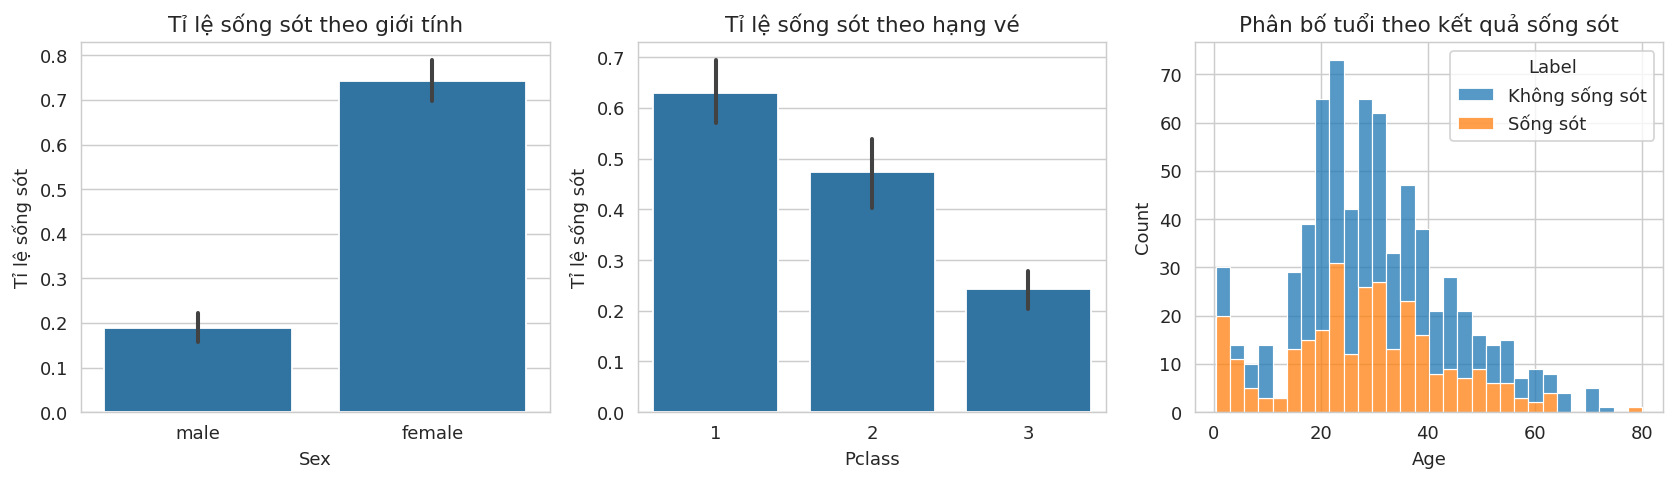

In [5]:
eda = train_df.assign(Label=train_df['Survived'].map({0: 'Không sống sót', 1: 'Sống sót'}))
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
sns.barplot(data=eda, x='Sex', y='Survived', ax=axs[0])
axs[0].set_title('Tỉ lệ sống sót theo giới tính'); axs[0].set_ylabel('Tỉ lệ sống sót')
sns.barplot(data=eda, x='Pclass', y='Survived', ax=axs[1])
axs[1].set_title('Tỉ lệ sống sót theo hạng vé'); axs[1].set_ylabel('Tỉ lệ sống sót')
sns.histplot(data=eda, x='Age', hue='Label', bins=30, multiple='stack', ax=axs[2])
axs[2].set_title('Phân bố tuổi theo kết quả sống sót')
plt.tight_layout(); plt.show()

## 1.4. Tiền xử lý dữ liệu

- Tạo đặc trưng mới: `Title` (danh xưng trích từ tên), `FamilySize`, `IsAlone`, `HasCabin`.
- Loại các cột không mang thông tin dự đoán: `PassengerId`, `Name`, `Ticket`, `Cabin` (thiếu hơn 77%).
- Chia train/valid theo tỉ lệ 80:20 (có phân tầng theo nhãn) **trước**, rồi mới điền khuyết bằng thống kê tính trên tập huấn luyện để tránh rò rỉ dữ liệu.
- Mã hóa: `Sex` → 0/1; `Embarked`, `Title` → one-hot. Cây quyết định không cần chuẩn hóa thang đo.

In [6]:
def engineer_features(df):
    """Tạo đặc trưng mới, mã hóa giới tính và bỏ các cột không dùng."""
    df = df.copy()
    df['Title'] = df['Name'].str.extract(r',\s*([^.]+)\.', expand=False).str.strip()
    df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
    df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Mrs', 'Miss', 'Master']), 'Rare')
    df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
    df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
    df['HasCabin'] = df['Cabin'].notnull().astype(int)
    df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
    return df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin'])

full = engineer_features(train_df)
y = full['Survived']
X = full.drop(columns='Survived')
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# Thống kê điền khuyết: chỉ tính trên tập huấn luyện
age_by_title = X_train.groupby('Title')['Age'].median()
fare_by_class = X_train.groupby('Pclass')['Fare'].median()
embarked_mode = X_train['Embarked'].mode()[0]

def impute_and_encode(df, columns=None):
    df = df.copy()
    df['Age'] = df['Age'].fillna(df['Title'].map(age_by_title))
    df['Fare'] = df['Fare'].fillna(df['Pclass'].map(fare_by_class))
    df['Embarked'] = df['Embarked'].fillna(embarked_mode)
    df = pd.get_dummies(df, columns=['Embarked', 'Title'], dtype=int)
    if columns is not None:                      # đồng bộ cột với tập huấn luyện
        df = df.reindex(columns=columns, fill_value=0)
    return df

X_train = impute_and_encode(X_train)
feature_names = X_train.columns.tolist()
X_valid = impute_and_encode(X_valid, feature_names)

print('Tập huấn luyện:', X_train.shape, '| Tập kiểm tra:', X_valid.shape)
print('Số giá trị thiếu còn lại:', int(X_train.isnull().sum().sum() + X_valid.isnull().sum().sum()))
print('Các đặc trưng:', feature_names)
display(X_train.head())

Tập huấn luyện: (712, 17) | Tập kiểm tra: (179, 17)
Số giá trị thiếu còn lại: 0
Các đặc trưng: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,HasCabin,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
599,1,0,49.0,1,0,56.9292,2,0,1,1,0,0,0,0,0,0,1
155,1,0,51.0,0,1,61.3792,2,0,0,1,0,0,0,0,1,0,0
604,1,0,35.0,0,0,26.5500,1,1,0,1,0,0,0,0,1,0,0
66,2,1,29.0,0,0,10.5000,1,1,1,0,0,1,0,0,0,1,0
310,1,1,24.0,0,0,83.1583,1,1,1,1,0,0,0,1,0,0,0


## 1.5. Nhiệm vụ 1: Xây dựng cây quyết định
Cây có độ sâu tối đa 3 để dễ quan sát cách cây ra quyết định.

Accuracy tập huấn luyện: 0.8329
Accuracy tập kiểm tra  : 0.8156


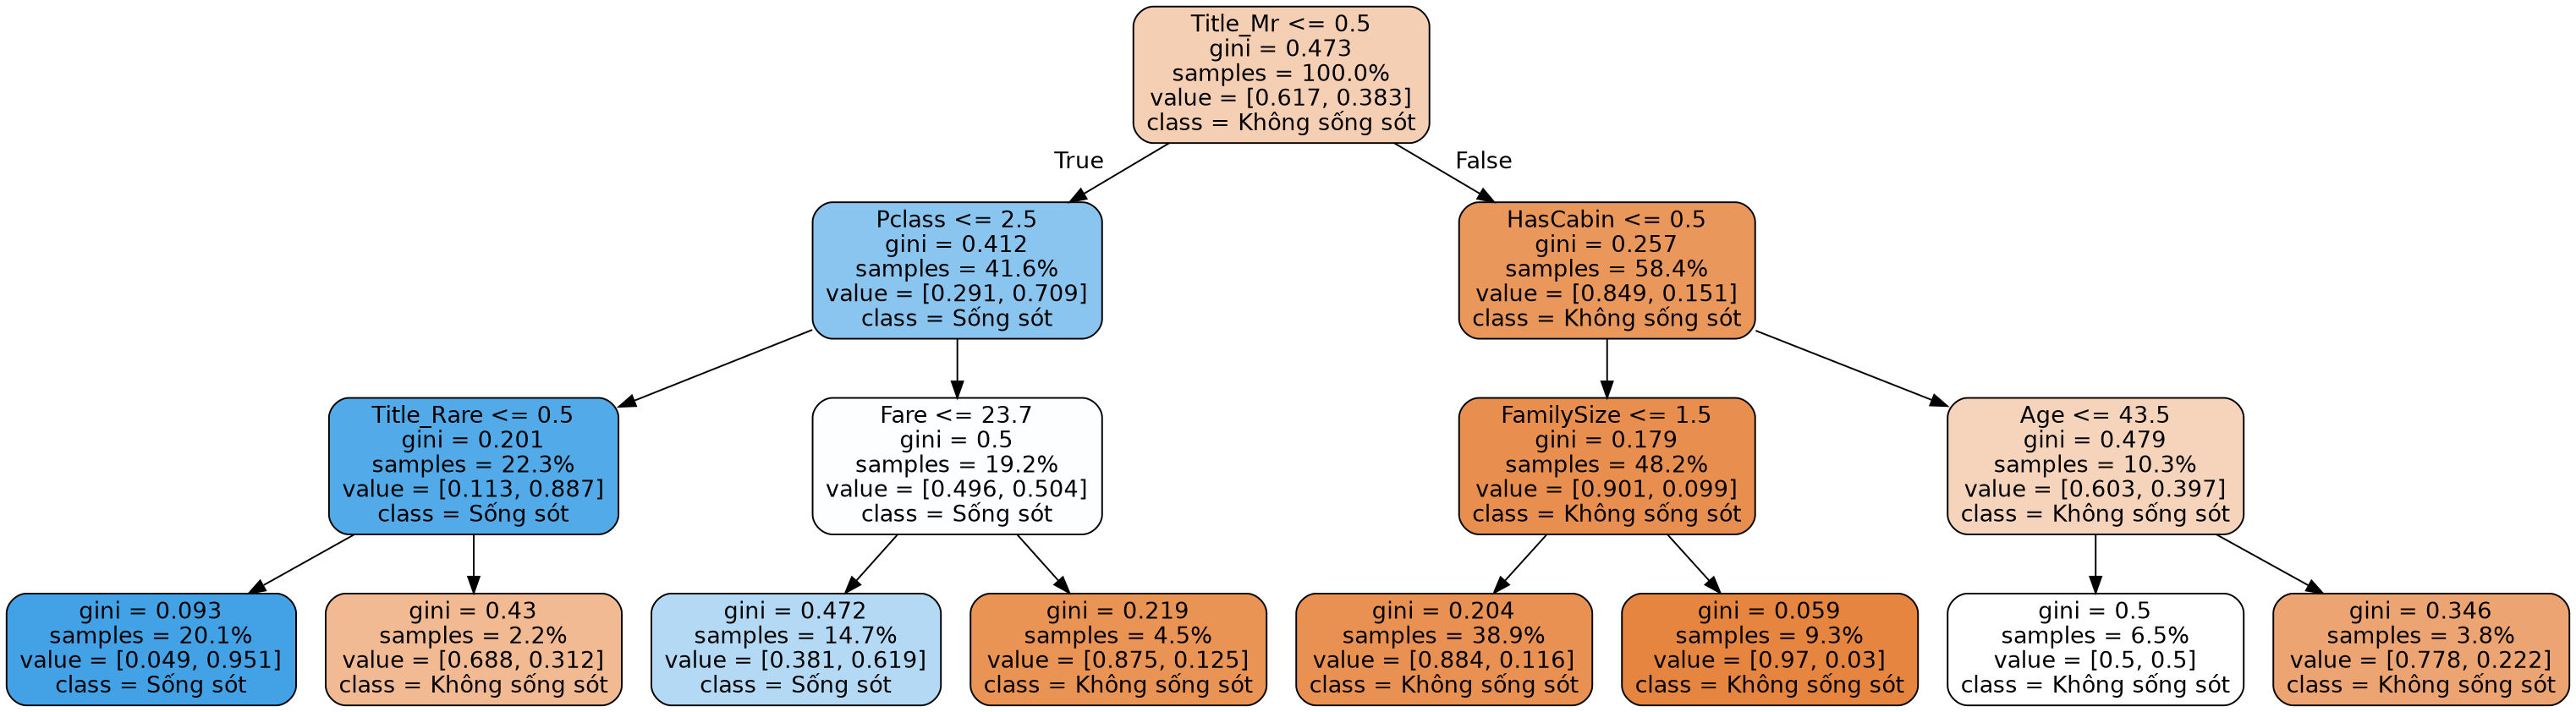

In [7]:
dt = tree.DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
dt.fit(X_train, y_train)
print(f'Accuracy tập huấn luyện: {dt.score(X_train, y_train):.4f}')
print(f'Accuracy tập kiểm tra  : {dt.score(X_valid, y_valid):.4f}')
show_tree(dt, feature_names, ['Không sống sót', 'Sống sót'])

## 1.6. Nhiệm vụ 2: Tìm tham số tối ưu cho cây quyết định bằng GridSearchCV
- `scoring='roc_auc'`: chọn mô hình theo diện tích dưới đường ROC.
- `cv=4`: kiểm định chéo 4 fold.
- `return_train_score=True`: trả về cả điểm huấn luyện để đánh giá bias/variance (overfitting).

In [8]:
params = {'max_depth': [1, 2, 3, 4, 5, 6, 8, 10, 12]}
cv_dt = GridSearchCV(tree.DecisionTreeClassifier(random_state=RANDOM_STATE),
                     param_grid=params, scoring='roc_auc', n_jobs=None, refit=True,
                     cv=N_FOLDS, verbose=1, error_score=np.nan, return_train_score=True)
cv_dt.fit(X_train, y_train)

print('Tham số tốt nhất:', cv_dt.best_params_, '| ROC AUC (CV):', round(cv_dt.best_score_, 4))
res = pd.DataFrame(cv_dt.cv_results_)
display(res[['param_max_depth', 'mean_train_score', 'mean_test_score', 'std_test_score']].round(4))

Fitting 4 folds for each of 9 candidates, totalling 36 fits
Tham số tốt nhất: {'max_depth': 3} | ROC AUC (CV): 0.8623


,param_max_depth,mean_train_score,mean_test_score,std_test_score
0,1,0.7867,0.7867,0.0556
1,2,0.8537,0.8483,0.0446
2,3,0.8861,0.8623,0.0332
3,4,0.9120,0.8488,0.0157
4,5,0.9319,0.8406,0.0293
5,6,0.9488,0.8360,0.0351
6,8,0.9724,0.8049,0.0386
7,10,0.9853,0.7820,0.0398
8,12,0.9924,0.7777,0.0373


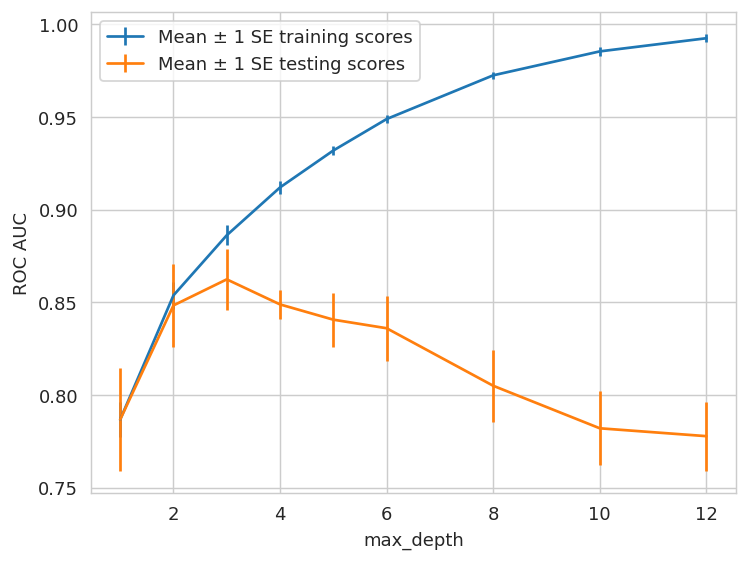

In [9]:
plot_depth_curve(cv_dt)

Mở rộng lưới tìm kiếm: ngoài `max_depth`, thử thêm `min_samples_leaf` (số mẫu tối thiểu ở nút lá) và `criterion` (`gini` hoặc `entropy`) để hạn chế quá khớp.

In [10]:
params2 = {'max_depth': [3, 4, 5, 6, 8],
           'min_samples_leaf': [1, 5, 10, 20],
           'criterion': ['gini', 'entropy']}
cv_dt2 = GridSearchCV(tree.DecisionTreeClassifier(random_state=RANDOM_STATE),
                      param_grid=params2, scoring='roc_auc', cv=N_FOLDS,
                      return_train_score=True)
cv_dt2.fit(X_train, y_train)
dt_best = cv_dt2.best_estimator_
print('Tham số tốt nhất:', cv_dt2.best_params_)
print('ROC AUC (CV)    :', round(cv_dt2.best_score_, 4))

Tham số tốt nhất: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10}
ROC AUC (CV)    : 0.8643


## 1.7. Nhiệm vụ 3: Xây dựng rừng cây (Random Forest)
Bước 1: giữ nguyên các tham số khác, tìm số cây `n_estimators` từ 10 đến 100 (bước 10), theo bài mẫu.

In [11]:
rf = RandomForestClassifier(n_estimators=10, criterion='gini', max_depth=5,
                            min_samples_split=2, min_samples_leaf=1,
                            max_features='sqrt', bootstrap=True, oob_score=False,
                            n_jobs=None, random_state=4, verbose=0, class_weight=None)

rf_params_ex = {'n_estimators': list(range(10, 110, 10))}
cv_rf_ex = GridSearchCV(rf, param_grid=rf_params_ex, scoring='roc_auc', n_jobs=None,
                        refit=True, cv=N_FOLDS, verbose=1, error_score=np.nan,
                        return_train_score=True)
cv_rf_ex.fit(X_train, y_train)
print('Tham số tốt nhất:', cv_rf_ex.best_params_, '| ROC AUC (CV):', round(cv_rf_ex.best_score_, 4))
res = pd.DataFrame(cv_rf_ex.cv_results_)
display(res[['param_n_estimators', 'mean_fit_time', 'mean_test_score', 'std_test_score']].round(4))

Fitting 4 folds for each of 10 candidates, totalling 40 fits
Tham số tốt nhất: {'n_estimators': 90} | ROC AUC (CV): 0.8745


,param_n_estimators,mean_fit_time,mean_test_score,std_test_score
0,10,0.0161,0.8642,0.0308
1,20,0.0293,0.8717,0.0330
2,30,0.0423,0.8688,0.0363
3,40,0.0540,0.8718,0.0374
4,50,0.0676,0.8726,0.0365
5,60,0.0798,0.8717,0.0358
6,70,0.0942,0.8726,0.0373
7,80,0.1039,0.8738,0.0347
8,90,0.1243,0.8745,0.0338
9,100,0.1499,0.8741,0.0340


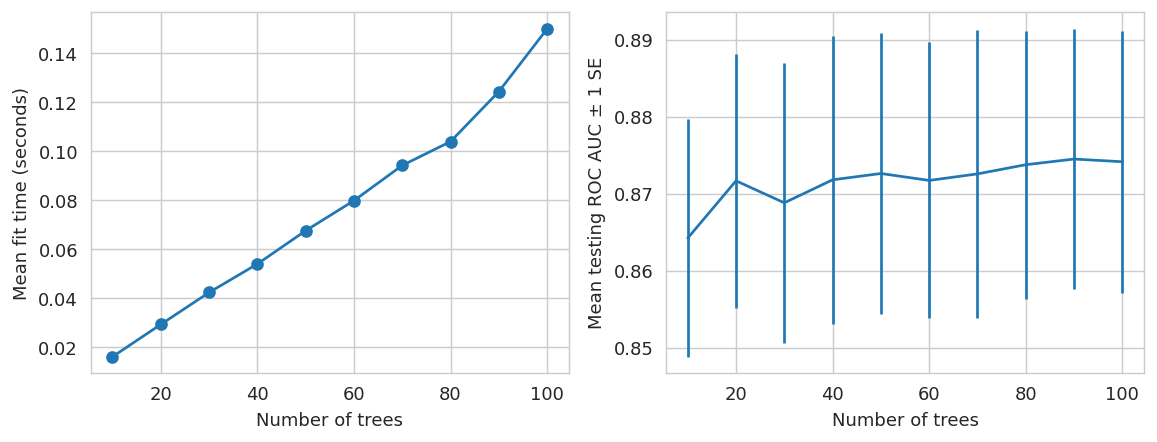

In [12]:
plot_rf_curve(cv_rf_ex)

Bước 2: với số cây tốt nhất ở trên, tinh chỉnh thêm `max_depth`, `min_samples_leaf` và `max_features`.

In [13]:
best_n = cv_rf_ex.best_params_['n_estimators']
rf2 = RandomForestClassifier(n_estimators=best_n, random_state=4)
rf_params2 = {'max_depth': [3, 5, 7, 9, None],
              'min_samples_leaf': [1, 3, 5],
              'max_features': ['sqrt', 0.5]}
cv_rf2 = GridSearchCV(rf2, param_grid=rf_params2, scoring='roc_auc',
                      cv=N_FOLDS, return_train_score=True)
cv_rf2.fit(X_train, y_train)
rf_best = cv_rf2.best_estimator_
print('Tham số tốt nhất:', cv_rf2.best_params_)
print('ROC AUC (CV)    :', round(cv_rf2.best_score_, 4))

Tham số tốt nhất: {'max_depth': 7, 'max_features': 0.5, 'min_samples_leaf': 1}
ROC AUC (CV)    : 0.8772


## 1.8. Mức độ quan trọng của từng đặc trưng

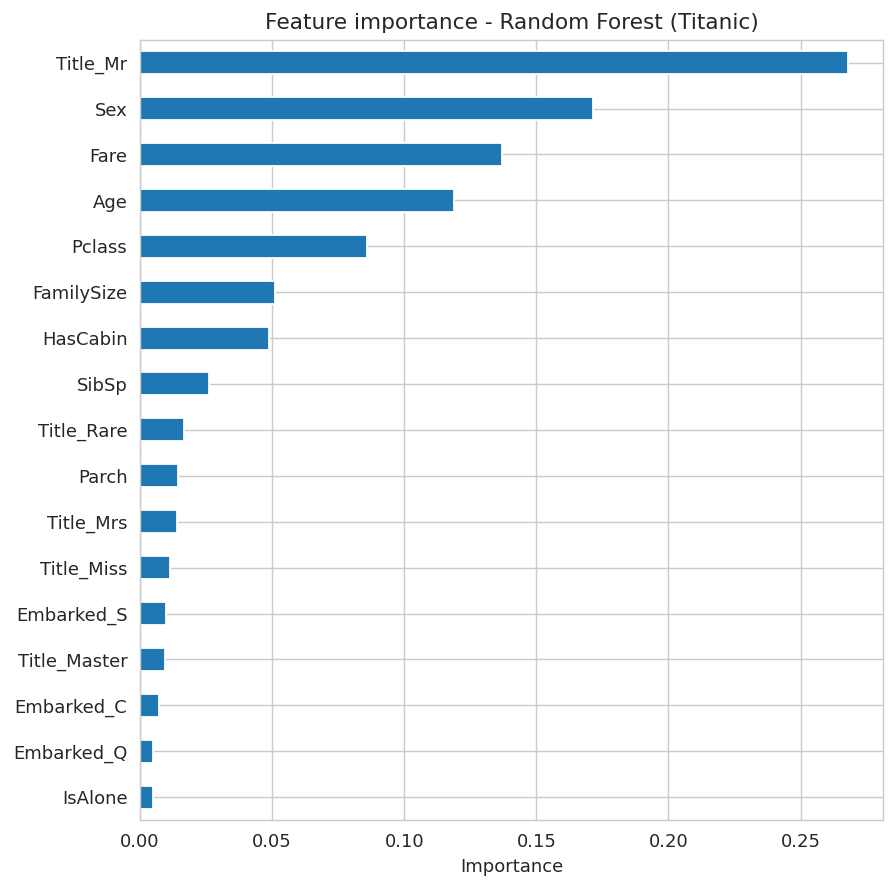

Title_Mr      0.2680
Sex           0.1715
Fare          0.1371
Age           0.1187
Pclass        0.0859
FamilySize    0.0511
dtype: float64


In [14]:
imp_rf = plot_importance(rf_best, feature_names, 'Feature importance - Random Forest (Titanic)')
print(imp_rf.head(6).round(4))

## 1.9. Đánh giá và so sánh mô hình trên tập kiểm tra

In [15]:
results = pd.concat([
    evaluate(dt, X_train, y_train, X_valid, y_valid, 'Cây quyết định (depth=3)'),
    evaluate(dt_best, X_train, y_train, X_valid, y_valid, 'Cây quyết định (tối ưu)'),
    evaluate(rf_best, X_train, y_train, X_valid, y_valid, 'Random Forest (tối ưu)'),
], ignore_index=True)
display(results.round(4))

,model,tập,accuracy,precision,recall,f1,roc_auc
0,Cây quyết định (depth=3),train,0.8329,0.8105,0.7363,0.7716,0.8843
1,Cây quyết định (depth=3),valid,0.8156,0.8000,0.6957,0.7442,0.8279
2,Cây quyết định (tối ưu),train,0.8413,0.8509,0.7106,0.7745,0.9069
3,Cây quyết định (tối ưu),valid,0.8101,0.8070,0.6667,0.7302,0.8447
4,Random Forest (tối ưu),train,0.9129,0.9137,0.8535,0.8826,0.9636
5,Random Forest (tối ưu),valid,0.8492,0.8500,0.7391,0.7907,0.8624


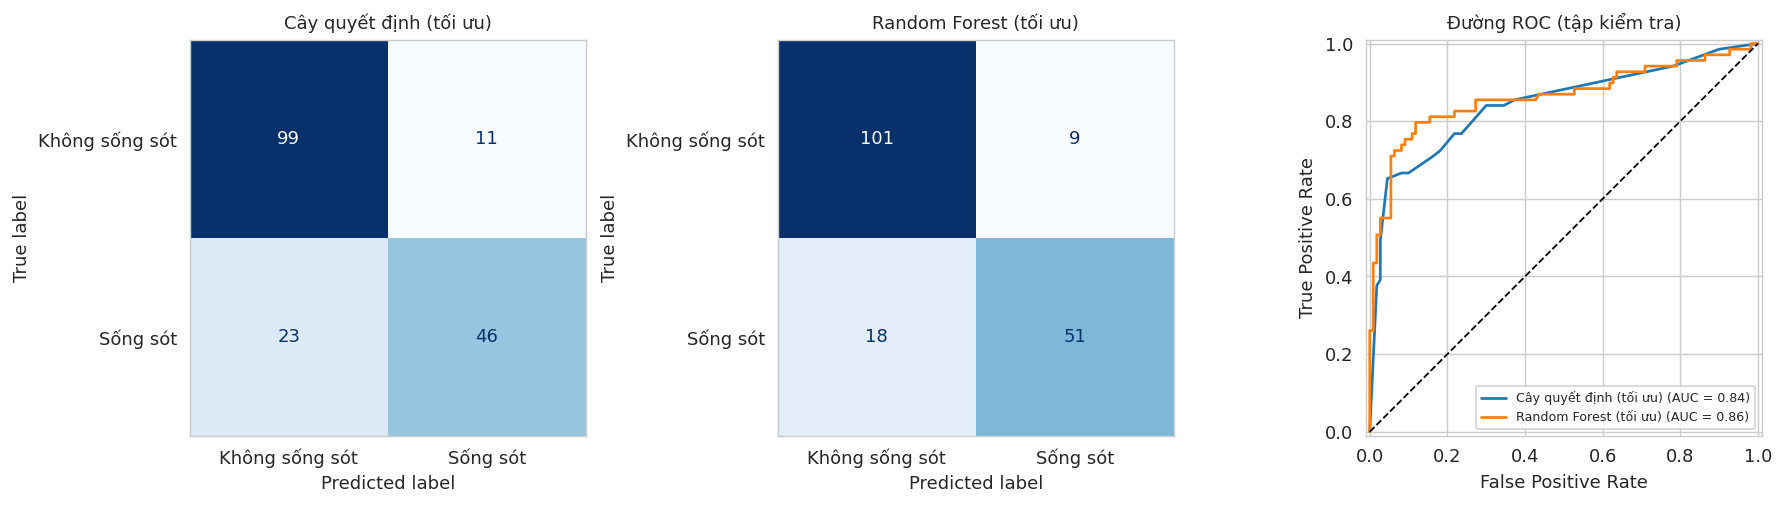

                precision    recall  f1-score   support

Không sống sót     0.8487    0.9182    0.8821       110
      Sống sót     0.8500    0.7391    0.7907        69

      accuracy                         0.8492       179
     macro avg     0.8494    0.8287    0.8364       179
  weighted avg     0.8492    0.8492    0.8469       179



In [16]:
plot_confusion_and_roc({'Cây quyết định (tối ưu)': dt_best, 'Random Forest (tối ưu)': rf_best},
                       X_valid, y_valid, ['Không sống sót', 'Sống sót'])
print(classification_report(y_valid, rf_best.predict(X_valid),
                            target_names=['Không sống sót', 'Sống sót'], digits=4))

## 1.10. Dự đoán trên `test.csv`
`test.csv` không có nhãn nên không thể tính độ chính xác; ở đây chỉ áp dụng cùng các bước tiền xử lý rồi dự đoán và lưu kết quả.

In [17]:
X_test = impute_and_encode(engineer_features(test_df), feature_names)
submission = pd.DataFrame({'PassengerId': test_df['PassengerId'],
                           'Survived': rf_best.predict(X_test)})
submission.to_csv('titanic_submission.csv', index=False)
print('Số dự đoán:', len(submission))
print(submission['Survived'].value_counts().rename({0: 'Không sống sót', 1: 'Sống sót'}))
display(submission.head())

Số dự đoán: 418
Survived
Không sống sót    261
Sống sót          157
Name: count, dtype: int64


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1


### Nhận xét bài 1 (Titanic)

- **Dữ liệu:** `Age` thiếu 19,9%, `Cabin` thiếu 77,1%, `Embarked` thiếu 2 dòng; không có dòng trùng lặp. Lớp "sống sót" chiếm 38,4% nên dữ liệu hơi lệch nhưng chưa nghiêm trọng.
- **Cây quyết định:** khi tăng `max_depth` từ 1 lên 12, ROC AUC trên tập huấn luyện tăng liên tục (0,787 → 0,992) trong khi ROC AUC kiểm định chéo đạt đỉnh ở độ sâu 3 (0,862) rồi giảm xuống 0,778. Đây là dấu hiệu **overfitting**: cây càng sâu càng học thuộc dữ liệu huấn luyện. Lưới mở rộng chọn `criterion='entropy'`, `max_depth=5`, `min_samples_leaf=10` (AUC CV 0,864), chỉ nhỉnh hơn 0,002 so với cây độ sâu 3.
- **Rừng cây:** AUC kiểm định chéo chỉ tăng từ 0,864 (10 cây) lên 0,875 (90 cây) và gần như phẳng sau khoảng 20 cây, trong khi thời gian huấn luyện tăng gần tuyến tính (0,016 s → 0,159 s). Sai số chuẩn khoảng 0,03 lớn hơn nhiều so với chênh lệch giữa các mức, nên không nên chọn quá nhiều cây. Sau khi tinh chỉnh, mô hình tốt nhất có `max_depth=7`, `max_features=0.5`, `min_samples_leaf=1`, AUC CV 0,877.
- **Đặc trưng quan trọng:** `Title_Mr` (0,268), `Sex` (0,172), `Fare` (0,137), `Age` (0,119), `Pclass` (0,086). Điều này khớp với EDA: phụ nữ và hành khách hạng vé cao có tỉ lệ sống sót cao hơn.
- **So sánh trên tập kiểm tra (179 hành khách):** Random Forest đạt accuracy 0,849 và ROC AUC 0,862, cao hơn cây quyết định tối ưu (0,810 và 0,845); recall của lớp "sống sót" tăng từ 0,667 lên 0,739. Tuy nhiên Random Forest vẫn còn chênh lệch giữa tập huấn luyện (accuracy 0,913) và tập kiểm tra (0,849), tức vẫn overfitting ở mức vừa phải. Tập kiểm tra nhỏ nên chênh lệch vài điểm phần trăm chưa chắc có ý nghĩa thống kê.
- **Dự đoán `test.csv`:** 157/418 hành khách (37,6%) được dự đoán sống sót, gần với tỉ lệ 38,4% của tập huấn luyện. Vì `test.csv` không có nhãn nên không tính được độ chính xác trên tập này.

---
# BÀI 2: CÂY QUYẾT ĐỊNH VÀ RỪNG CÂY TRÊN DỮ LIỆU BỆNH TIỂU ĐƯỜNG

Bộ dữ liệu `diabetes_prediction_dataset.csv` gồm 100.000 hồ sơ bệnh nhân với các thông tin nhân khẩu học và chỉ số lâm sàng. Biến mục tiêu `diabetes` (1 = mắc bệnh, 0 = không mắc).

## 2.1. Đọc dữ liệu

In [18]:
df = pd.read_csv(f'{DATA_DIR}/diabetes_prediction_dataset.csv')
print(f'Kích thước dữ liệu: {df.shape}')
display(df.head())
df.info()

Kích thước dữ liệu: (100000, 9)


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  str    
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  str    
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), str(2)
memory usage: 6.9 MB


## 2.2. Kiểm tra chất lượng dữ liệu

In [19]:
print('Số giá trị thiếu mỗi cột:'); print(df.isnull().sum().to_string())
print('\nSố dòng trùng lặp:', df.duplicated().sum())
print('\nPhân bố giới tính:'); print(df['gender'].value_counts().to_string())
print('\nPhân bố tiền sử hút thuốc:'); print(df['smoking_history'].value_counts().to_string())
print('\nTỉ lệ các lớp của biến mục tiêu:')
print(df['diabetes'].value_counts(normalize=True).round(4).to_string())
display(df.describe().T.round(3))

Số giá trị thiếu mỗi cột:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0

Số dòng trùng lặp: 3854

Phân bố giới tính:
gender
Female    58552
Male      41430
Other        18

Phân bố tiền sử hút thuốc:
smoking_history
No Info        35816
never          35095
former          9352
current         9286
not current     6447
ever            4004

Tỉ lệ các lớp của biến mục tiêu:
diabetes
0    0.915
1    0.085


,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.886,22.517,0.08,24.00,43.00,60.00,80.00
hypertension,100000.0,0.075,0.263,0.00,0.00,0.00,0.00,1.00
heart_disease,100000.0,0.039,0.195,0.00,0.00,0.00,0.00,1.00
bmi,100000.0,27.321,6.637,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.528,1.071,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058,40.708,80.00,100.00,140.00,159.00,300.00
diabetes,100000.0,0.085,0.279,0.00,0.00,0.00,0.00,1.00


Dữ liệu không có giá trị thiếu nhưng có dòng trùng lặp, cần loại bỏ để tránh cùng một bản ghi xuất hiện ở cả tập huấn luyện lẫn tập kiểm tra. Nhóm `No Info` của `smoking_history` được giữ lại như một giá trị riêng.

In [20]:
df = df.drop_duplicates().reset_index(drop=True)
print('Kích thước sau khi loại bỏ trùng lặp:', df.shape)
print('Tỉ lệ mắc bệnh:', round(df['diabetes'].mean(), 4))

Kích thước sau khi loại bỏ trùng lặp: (96146, 9)
Tỉ lệ mắc bệnh: 0.0882


## 2.3. Khám phá dữ liệu (EDA)

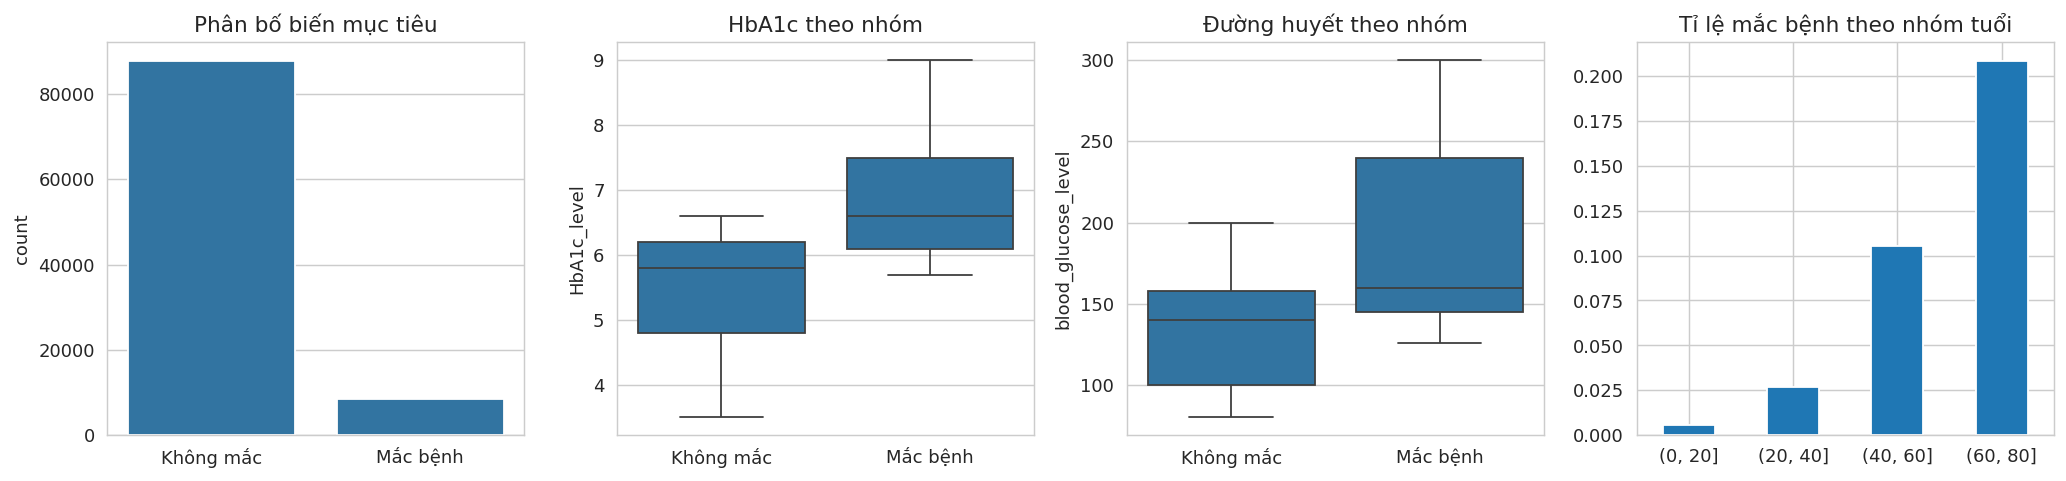

In [21]:
eda = df.assign(Label=df['diabetes'].map({0: 'Không mắc', 1: 'Mắc bệnh'}))
fig, axs = plt.subplots(1, 4, figsize=(16, 3.8))
sns.countplot(data=eda, x='Label', ax=axs[0]); axs[0].set_title('Phân bố biến mục tiêu'); axs[0].set_xlabel('')
sns.boxplot(data=eda, x='Label', y='HbA1c_level', ax=axs[1]); axs[1].set_title('HbA1c theo nhóm'); axs[1].set_xlabel('')
sns.boxplot(data=eda, x='Label', y='blood_glucose_level', ax=axs[2]); axs[2].set_title('Đường huyết theo nhóm'); axs[2].set_xlabel('')
age_rate = df.groupby(pd.cut(df['age'], [0, 20, 40, 60, 80]), observed=True)['diabetes'].mean()
age_rate.plot.bar(ax=axs[3], rot=0); axs[3].set_title('Tỉ lệ mắc bệnh theo nhóm tuổi'); axs[3].set_xlabel('')
plt.tight_layout(); plt.show()

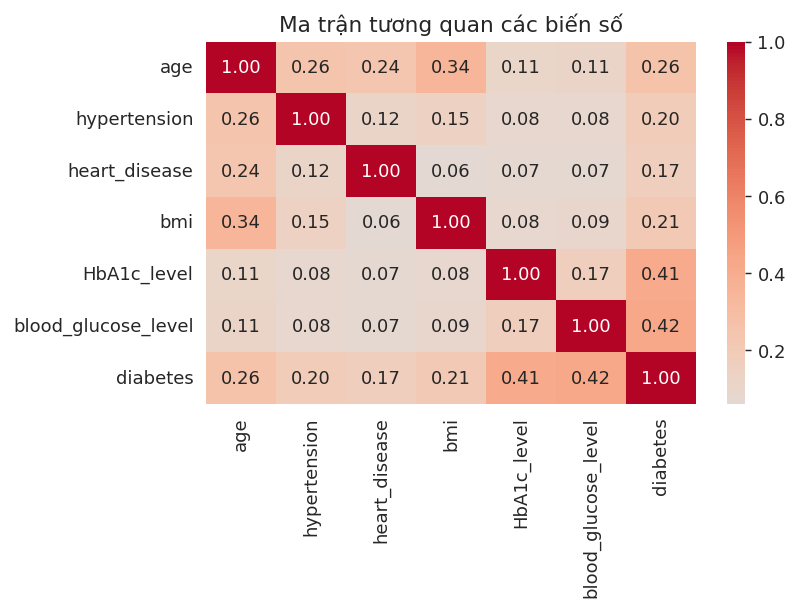

In [22]:
plt.figure(figsize=(6.5, 4.8))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Ma trận tương quan các biến số'); plt.tight_layout(); plt.show()

## 2.4. Tiền xử lý dữ liệu
- Mã hóa one-hot cho hai biến phân loại `gender` và `smoking_history`.
- Chia train/valid 80:20, **phân tầng theo nhãn** vì dữ liệu mất cân bằng.
- Không cần chuẩn hóa vì cây và rừng cây không phụ thuộc thang đo.

In [23]:
Xd = pd.get_dummies(df.drop(columns='diabetes'), columns=['gender', 'smoking_history'], dtype=int)
yd = df['diabetes']
Xd_train, Xd_valid, yd_train, yd_valid = train_test_split(
    Xd, yd, test_size=0.2, random_state=RANDOM_STATE, stratify=yd)
feature_names_d = Xd.columns.tolist()
print('Tập huấn luyện:', Xd_train.shape, '| Tập kiểm tra:', Xd_valid.shape)
print('Tỉ lệ mắc bệnh - train: %.4f | valid: %.4f' % (yd_train.mean(), yd_valid.mean()))
print('Các đặc trưng:', feature_names_d)

Tập huấn luyện: (76916, 15) | Tập kiểm tra: (19230, 15)
Tỉ lệ mắc bệnh - train: 0.0882 | valid: 0.0882
Các đặc trưng: ['age', 'hypertension', 'heart_disease', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'gender_Female', 'gender_Male', 'gender_Other', 'smoking_history_No Info', 'smoking_history_current', 'smoking_history_ever', 'smoking_history_former', 'smoking_history_never', 'smoking_history_not current']


## 2.5. Nhiệm vụ 1: Xây dựng cây quyết định (độ sâu 2)

Accuracy tập huấn luyện: 0.9707
Accuracy tập kiểm tra  : 0.9711


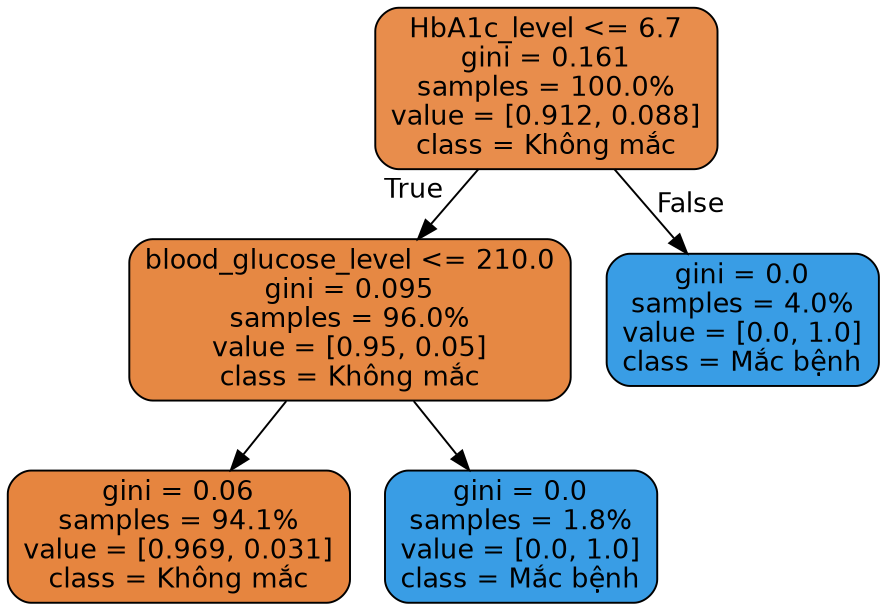

In [24]:
dt_d = tree.DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE)
dt_d.fit(Xd_train, yd_train)
print(f'Accuracy tập huấn luyện: {dt_d.score(Xd_train, yd_train):.4f}')
print(f'Accuracy tập kiểm tra  : {dt_d.score(Xd_valid, yd_valid):.4f}')
show_tree(dt_d, feature_names_d, ['Không mắc', 'Mắc bệnh'])

## 2.6. Nhiệm vụ 2: Tìm tham số tối ưu cho cây quyết định bằng GridSearchCV

In [25]:
params = {'max_depth': [1, 2, 4, 6, 8, 10, 12]}
cv_dt_d = GridSearchCV(tree.DecisionTreeClassifier(random_state=RANDOM_STATE),
                       param_grid=params, scoring='roc_auc', n_jobs=-1, refit=True,
                       cv=N_FOLDS, verbose=1, error_score=np.nan, return_train_score=True)
cv_dt_d.fit(Xd_train, yd_train)

print('Tham số tốt nhất:', cv_dt_d.best_params_, '| ROC AUC (CV):', round(cv_dt_d.best_score_, 4))
res = pd.DataFrame(cv_dt_d.cv_results_)
display(res[['param_max_depth', 'mean_train_score', 'mean_test_score', 'std_test_score']].round(4))

Fitting 4 folds for each of 7 candidates, totalling 28 fits
Tham số tốt nhất: {'max_depth': 10} | ROC AUC (CV): 0.9725


,param_max_depth,mean_train_score,mean_test_score,std_test_score
0,1,0.7291,0.7291,0.0059
1,2,0.8338,0.8338,0.0022
2,4,0.9351,0.9336,0.0041
3,6,0.9650,0.9631,0.0019
4,8,0.9738,0.9723,0.0013
5,10,0.9772,0.9725,0.0011
6,12,0.9807,0.9651,0.0022


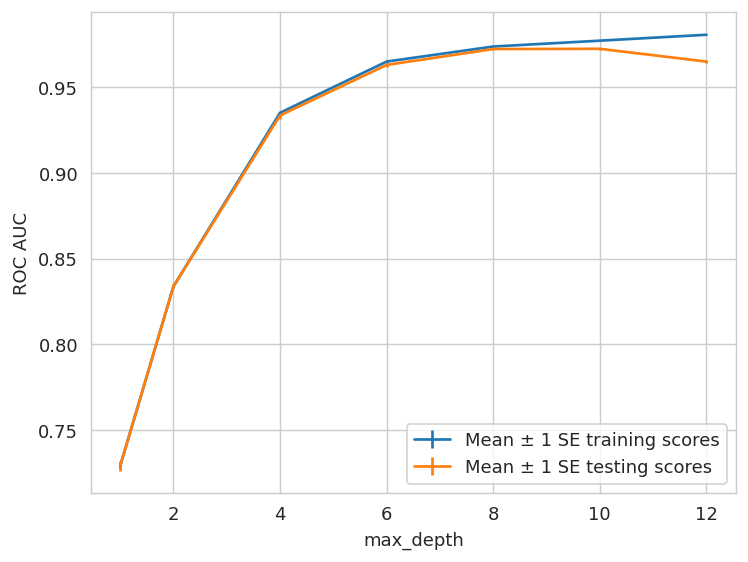

In [26]:
plot_depth_curve(cv_dt_d)

In [27]:
params2 = {'max_depth': [3, 4, 5, 6, 7, 8],
           'min_samples_leaf': [1, 10, 50, 100],
           'criterion': ['gini', 'entropy']}
cv_dt_d2 = GridSearchCV(tree.DecisionTreeClassifier(random_state=RANDOM_STATE),
                        param_grid=params2, scoring='roc_auc', n_jobs=-1,
                        cv=N_FOLDS, return_train_score=True)
cv_dt_d2.fit(Xd_train, yd_train)
dt_best_d = cv_dt_d2.best_estimator_
print('Tham số tốt nhất:', cv_dt_d2.best_params_)
print('ROC AUC (CV)    :', round(cv_dt_d2.best_score_, 4))

Tham số tốt nhất: {'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 100}
ROC AUC (CV)    : 0.9726


## 2.7. Nhiệm vụ 3: Xây dựng rừng cây (Random Forest)
Bước 1: tìm số cây `n_estimators` từ 10 đến 100 (bước 10).

In [28]:
rf_d = RandomForestClassifier(n_estimators=10, criterion='gini', max_depth=8,
                              min_samples_split=2, min_samples_leaf=1,
                              max_features='sqrt', bootstrap=True, n_jobs=-1,
                              random_state=4)
rf_params_ex = {'n_estimators': list(range(10, 110, 10))}
cv_rf_d = GridSearchCV(rf_d, param_grid=rf_params_ex, scoring='roc_auc', n_jobs=None,
                       refit=True, cv=N_FOLDS, verbose=1, error_score=np.nan,
                       return_train_score=True)
cv_rf_d.fit(Xd_train, yd_train)
print('Tham số tốt nhất:', cv_rf_d.best_params_, '| ROC AUC (CV):', round(cv_rf_d.best_score_, 4))
res = pd.DataFrame(cv_rf_d.cv_results_)
display(res[['param_n_estimators', 'mean_fit_time', 'mean_test_score', 'std_test_score']].round(4))

Fitting 4 folds for each of 10 candidates, totalling 40 fits
Tham số tốt nhất: {'n_estimators': 60} | ROC AUC (CV): 0.9651


,param_n_estimators,mean_fit_time,mean_test_score,std_test_score
0,10,0.2926,0.9632,0.0037
1,20,0.5292,0.9644,0.0030
2,30,0.7446,0.9647,0.0025
3,40,1.0139,0.9648,0.0026
4,50,1.4068,0.9647,0.0028
5,60,1.6279,0.9651,0.0026
6,70,1.7660,0.9651,0.0025
7,80,1.9533,0.9651,0.0025
8,90,2.1068,0.9648,0.0026
9,100,2.1915,0.9646,0.0026


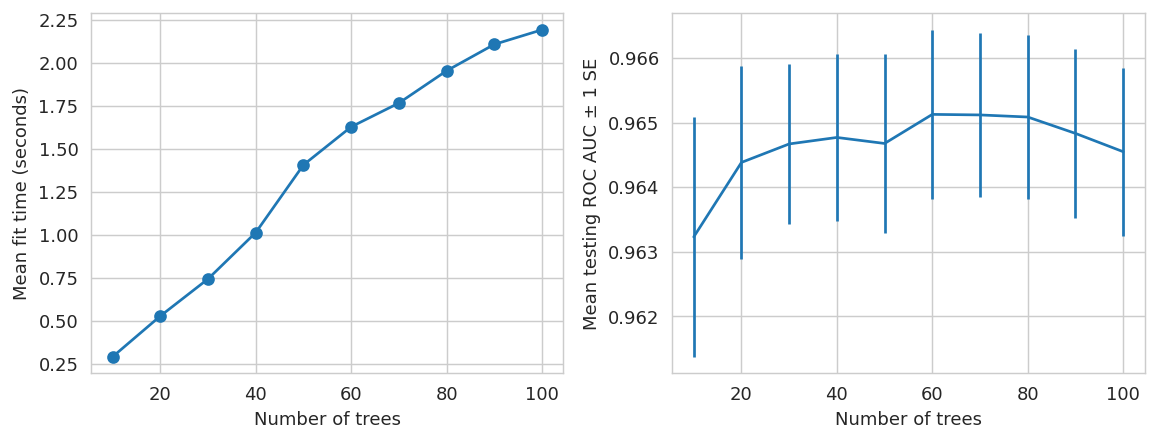

In [29]:
plot_rf_curve(cv_rf_d)

Bước 2: tinh chỉnh `max_depth` và `min_samples_leaf` với số cây tốt nhất.

In [30]:
best_n_d = cv_rf_d.best_params_['n_estimators']
rf_d2 = RandomForestClassifier(n_estimators=best_n_d, max_features='sqrt', n_jobs=-1, random_state=4)
rf_params2 = {'max_depth': [6, 8, 10, 12],
              'min_samples_leaf': [1, 5, 20]}
cv_rf_d2 = GridSearchCV(rf_d2, param_grid=rf_params2, scoring='roc_auc',
                        cv=N_FOLDS, return_train_score=True)
cv_rf_d2.fit(Xd_train, yd_train)
rf_best_d = cv_rf_d2.best_estimator_
print('Tham số tốt nhất:', cv_rf_d2.best_params_)
print('ROC AUC (CV)    :', round(cv_rf_d2.best_score_, 4))

Tham số tốt nhất: {'max_depth': 12, 'min_samples_leaf': 5}
ROC AUC (CV)    : 0.9711


## 2.8. Mức độ quan trọng của từng đặc trưng

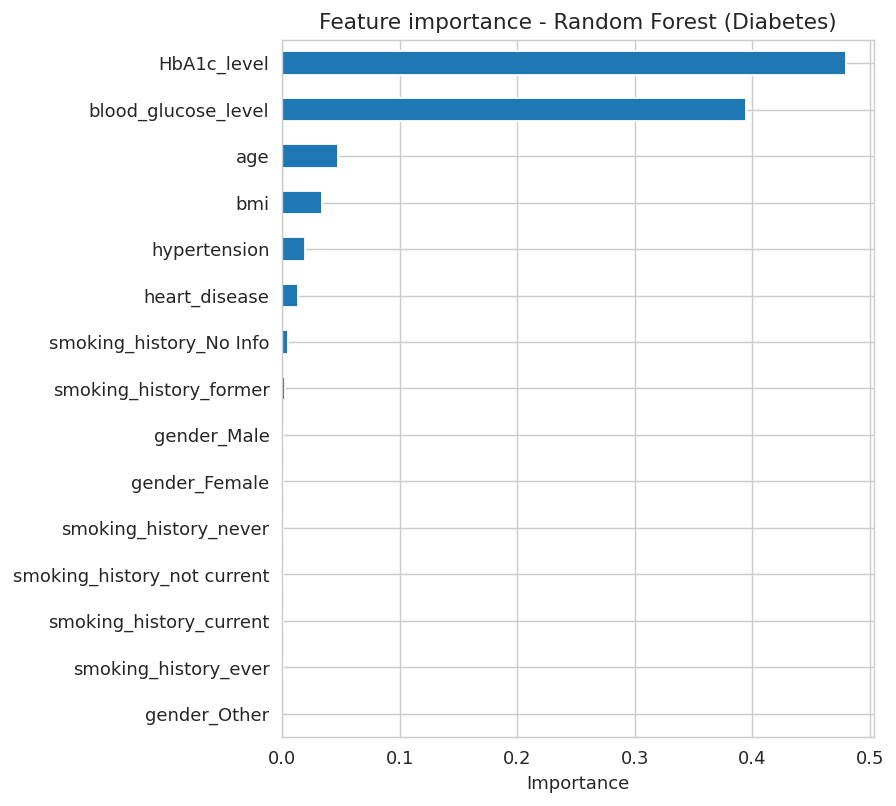

HbA1c_level            0.4800
blood_glucose_level    0.3944
age                    0.0479
bmi                    0.0336
hypertension           0.0196
heart_disease          0.0133
dtype: float64


In [31]:
imp_rf_d = plot_importance(rf_best_d, feature_names_d, 'Feature importance - Random Forest (Diabetes)')
print(imp_rf_d.head(6).round(4))

## 2.9. Đánh giá và so sánh mô hình trên tập kiểm tra
Do nhãn mất cân bằng (khoảng 8,8% mắc bệnh), accuracy dễ gây ngộ nhận; cần xem thêm **recall** của lớp mắc bệnh. Ngoài hai mô hình tối ưu theo ROC AUC, thử thêm Random Forest với `class_weight='balanced'` để tăng khả năng phát hiện ca bệnh.

In [32]:
rf_bal_d = RandomForestClassifier(n_estimators=best_n_d, max_depth=cv_rf_d2.best_params_['max_depth'],
                                  min_samples_leaf=cv_rf_d2.best_params_['min_samples_leaf'],
                                  class_weight='balanced', n_jobs=-1, random_state=4)
rf_bal_d.fit(Xd_train, yd_train)

results_d = pd.concat([
    evaluate(dt_d, Xd_train, yd_train, Xd_valid, yd_valid, 'Cây quyết định (depth=2)'),
    evaluate(dt_best_d, Xd_train, yd_train, Xd_valid, yd_valid, 'Cây quyết định (tối ưu)'),
    evaluate(rf_best_d, Xd_train, yd_train, Xd_valid, yd_valid, 'Random Forest (tối ưu)'),
    evaluate(rf_bal_d, Xd_train, yd_train, Xd_valid, yd_valid, 'Random Forest (balanced)'),
], ignore_index=True)
display(results_d.round(4))

,model,tập,accuracy,precision,recall,f1,roc_auc
0,Cây quyết định (depth=2),train,0.9707,1.0000,0.6677,0.8007,0.8338
1,Cây quyết định (depth=2),valid,0.9711,1.0000,0.6722,0.8039,0.8361
2,Cây quyết định (tối ưu),train,0.9709,0.9907,0.6762,0.8038,0.9737
3,Cây quyết định (tối ưu),valid,0.9709,0.9913,0.6757,0.8036,0.9732
4,Random Forest (tối ưu),train,0.9710,1.0000,0.6708,0.8030,0.9792
5,Random Forest (tối ưu),valid,0.9713,0.9991,0.6751,0.8058,0.9740
6,Random Forest (balanced),train,0.9165,0.5151,0.9176,0.6598,0.9816
7,Random Forest (balanced),valid,0.9118,0.4998,0.8992,0.6425,0.9772


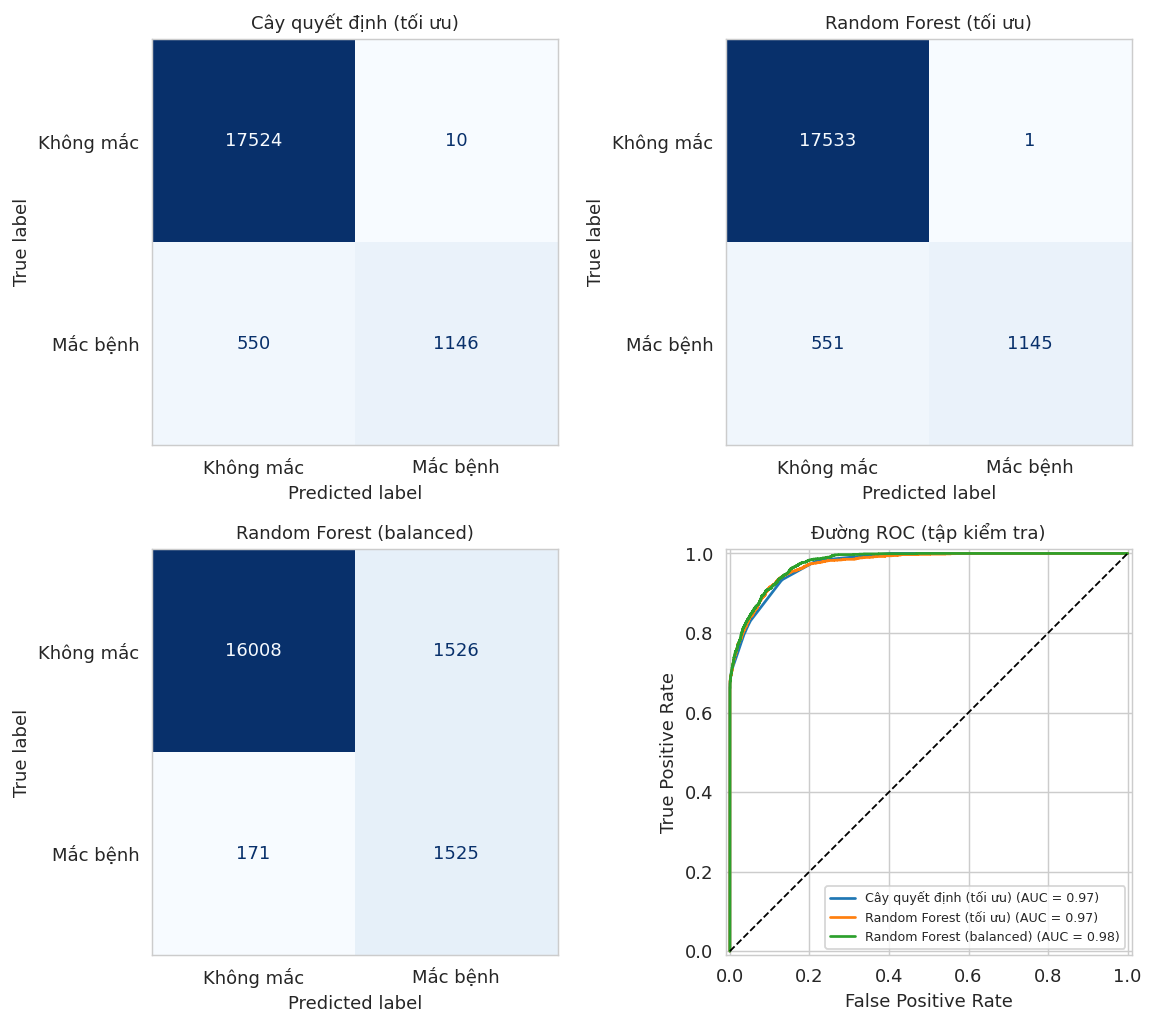

--- Random Forest (tối ưu) ---
              precision    recall  f1-score   support

   Không mắc     0.9695    0.9999    0.9845     17534
    Mắc bệnh     0.9991    0.6751    0.8058      1696

    accuracy                         0.9713     19230
   macro avg     0.9843    0.8375    0.8951     19230
weighted avg     0.9721    0.9713    0.9687     19230

--- Random Forest (balanced) ---
              precision    recall  f1-score   support

   Không mắc     0.9894    0.9130    0.9497     17534
    Mắc bệnh     0.4998    0.8992    0.6425      1696

    accuracy                         0.9118     19230
   macro avg     0.7446    0.9061    0.7961     19230
weighted avg     0.9463    0.9118    0.9226     19230



In [33]:
plot_confusion_and_roc({'Cây quyết định (tối ưu)': dt_best_d,
                        'Random Forest (tối ưu)': rf_best_d,
                        'Random Forest (balanced)': rf_bal_d},
                       Xd_valid, yd_valid, ['Không mắc', 'Mắc bệnh'])
print('--- Random Forest (tối ưu) ---')
print(classification_report(yd_valid, rf_best_d.predict(Xd_valid), target_names=['Không mắc', 'Mắc bệnh'], digits=4))
print('--- Random Forest (balanced) ---')
print(classification_report(yd_valid, rf_bal_d.predict(Xd_valid), target_names=['Không mắc', 'Mắc bệnh'], digits=4))

### Nhận xét bài 2 (Diabetes)

- **Dữ liệu:** không có giá trị thiếu nhưng có 3.854 dòng trùng lặp (3,9%), sau khi loại bỏ còn 96.146 dòng. Lớp "mắc bệnh" chỉ chiếm 8,8% nên dữ liệu **mất cân bằng**, vì vậy phải chia tập có phân tầng và không thể chỉ dựa vào accuracy.
- **Đặc trưng chi phối:** `HbA1c_level` (0,480) và `blood_glucose_level` (0,394) chiếm hơn 87% tổng độ quan trọng; tuổi, BMI, tăng huyết áp, bệnh tim đóng góp rất ít. Kiểm tra trực tiếp trên dữ liệu cho thấy mọi bản ghi có HbA1c ≥ 6,8 hoặc đường huyết > 200 đều mắc bệnh.
- **Cây quyết định:** cây độ sâu 2 đã đạt accuracy 0,971, nhưng ROC AUC chỉ 0,836. ROC AUC kiểm định chéo tăng mạnh đến độ sâu 8–10 (0,972), sau đó giảm ở độ sâu 12 (0,965) trong khi điểm huấn luyện vẫn tăng (0,981), tức bắt đầu overfitting nhẹ. Lưới mở rộng chọn `max_depth=8`, `min_samples_leaf=100` (AUC CV 0,9726).
- **Rừng cây:** AUC kiểm định chéo gần như phẳng từ khoảng 30 cây (0,9647 → 0,9651), còn thời gian huấn luyện tăng từ 0,31 s lên 2,36 s khi dùng 100 cây. Mô hình tinh chỉnh có `max_depth=12`, `min_samples_leaf=5` (AUC CV 0,9711).
- **Rừng cây không vượt trội cây quyết định ở bài này:** trên tập kiểm tra, cây tối ưu đạt accuracy 0,9709, ROC AUC 0,9732; Random Forest đạt 0,9713 và 0,9740. Chênh lệch gần như không đáng kể, vì tín hiệu chính nằm ở hai đặc trưng và dữ liệu đủ lớn để một cây đơn lẻ đã học tốt.
- **Điểm yếu cần chú ý:** cả hai mô hình có precision rất cao (≈ 0,99–1,00) nhưng recall của lớp mắc bệnh chỉ khoảng 0,675, nghĩa là bỏ sót khoảng một phần ba ca bệnh. Trong nhóm HbA1c từ 5,7 đến 6,6, tỉ lệ mắc bệnh chỉ khoảng 8% và gần như không đổi theo giá trị HbA1c, nên các đặc trưng hiện có không tách được nhóm này.
- **Đánh đổi precision/recall:** Random Forest với `class_weight='balanced'` nâng recall lên 0,899 nhưng precision giảm còn 0,500 và accuracy giảm còn 0,912. Trong sàng lọc y tế, ưu tiên bắt được ca bệnh (recall cao) thường quan trọng hơn, nhưng cái giá là nhiều cảnh báo nhầm hơn.

---
## Kết luận chung

| | Titanic | Diabetes |
|---|---|---|
| Độ sâu cây tốt nhất (CV) | 3 (lưới mở rộng: 5) | 8–10 |
| Mô hình tốt hơn trên tập kiểm tra | Random Forest | Gần như ngang nhau |
| Vấn đề chính | Overfitting khi cây sâu, tập dữ liệu nhỏ | Mất cân bằng lớp, recall thấp |
| Cách cải thiện đã thử | Tinh chỉnh `min_samples_leaf`, `max_features` | `class_weight='balanced'` |

- Cây quyết định dễ giải thích nhưng rất nhạy với độ sâu; luôn cần kiểm định chéo và so sánh điểm huấn luyện với điểm kiểm định để phát hiện overfitting.
- Random Forest giảm phương sai và thường cho kết quả ổn định hơn, nhưng lợi ích phụ thuộc vào dữ liệu: rõ ở Titanic, không đáng kể ở Diabetes.
- Với dữ liệu mất cân bằng cần chọn thước đo phù hợp (recall, F1, ROC AUC) thay vì chỉ accuracy.